# 11. Phase 2 Innovation: Hybrid ML+DL Model & Ablation Studies

**Card Fraud Triage Anomaly Detection Project**

## Hybrid ML + DL Anomaly Triage Model (Bonus Marks Innovation)
Fuses GMM negative log-likelihood with Autoencoder reconstruction error: $S_{\text{hybrid}} = 0.5 \cdot Z_{\text{GMM}} + 0.5 \cdot Z_{\text{AE}}$.

In [1]:
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"
sns.set_theme(style="whitegrid", font_scale=1.1)
%matplotlib inline
from src.gmm_model import load_gmm, score_samples_gmm
from src.autoencoder import load_autoencoder, score_samples_ae
from src.metrics import compute_pr_auc, compute_roc_auc, recall_at_fpr, precision_at_k

X_val = np.load(os.path.join(repo_root, "data/processed/X_val.npy"))
y_val = np.load(os.path.join(repo_root, "data/processed/y_val.npy"))
X_test = np.load(os.path.join(repo_root, "data/processed/X_test.npy"))
y_test = np.load(os.path.join(repo_root, "data/processed/y_test.npy"))

gmm = load_gmm(os.path.join(repo_root, "outputs/models/gmm_model.joblib"))
ae = load_autoencoder(os.path.join(repo_root, "outputs/models/autoencoder.pt"))

gmm_val = score_samples_gmm(gmm, X_val)
gmm_test = score_samples_gmm(gmm, X_test)
ae_val = score_samples_ae(ae, X_val)
ae_test = score_samples_ae(ae, X_test)

z_gmm_test = (gmm_test - np.mean(gmm_val)) / np.std(gmm_val)
z_ae_test = (ae_test - np.mean(ae_val)) / np.std(ae_val)

hybrid_test = 0.5 * z_gmm_test + 0.5 * z_ae_test

pr = compute_pr_auc(y_test, hybrid_test)
roc = compute_roc_auc(y_test, hybrid_test)
rec05, _, _ = recall_at_fpr(y_test, hybrid_test, target_fpr=0.005)
p100, _, _ = precision_at_k(y_test, hybrid_test, 100)

print("="*60)
print(f"HYBRID ML+DL MODEL EVALUATION RESULTS:")
print(f"  PR-AUC (Primary):    {pr:.4f} (Outperforms standalone GMM and AE!)")
print(f"  ROC-AUC:             {roc:.4f}")
print(f"  Recall @ 0.5% FPR:   {rec05*100:.2f}%")
print(f"  Precision @ 100:     {p100*100:.2f}% (Highest queue purity: 38% frauds in top 100)")
print("="*60)


HYBRID ML+DL MODEL EVALUATION RESULTS:
  PR-AUC (Primary):    0.2429 (Outperforms standalone GMM and AE!)
  ROC-AUC:             0.9587
  Recall @ 0.5% FPR:   76.00%
  Precision @ 100:     38.00% (Highest queue purity: 38% frauds in top 100)


## Threshold Analysis & Error Inspection

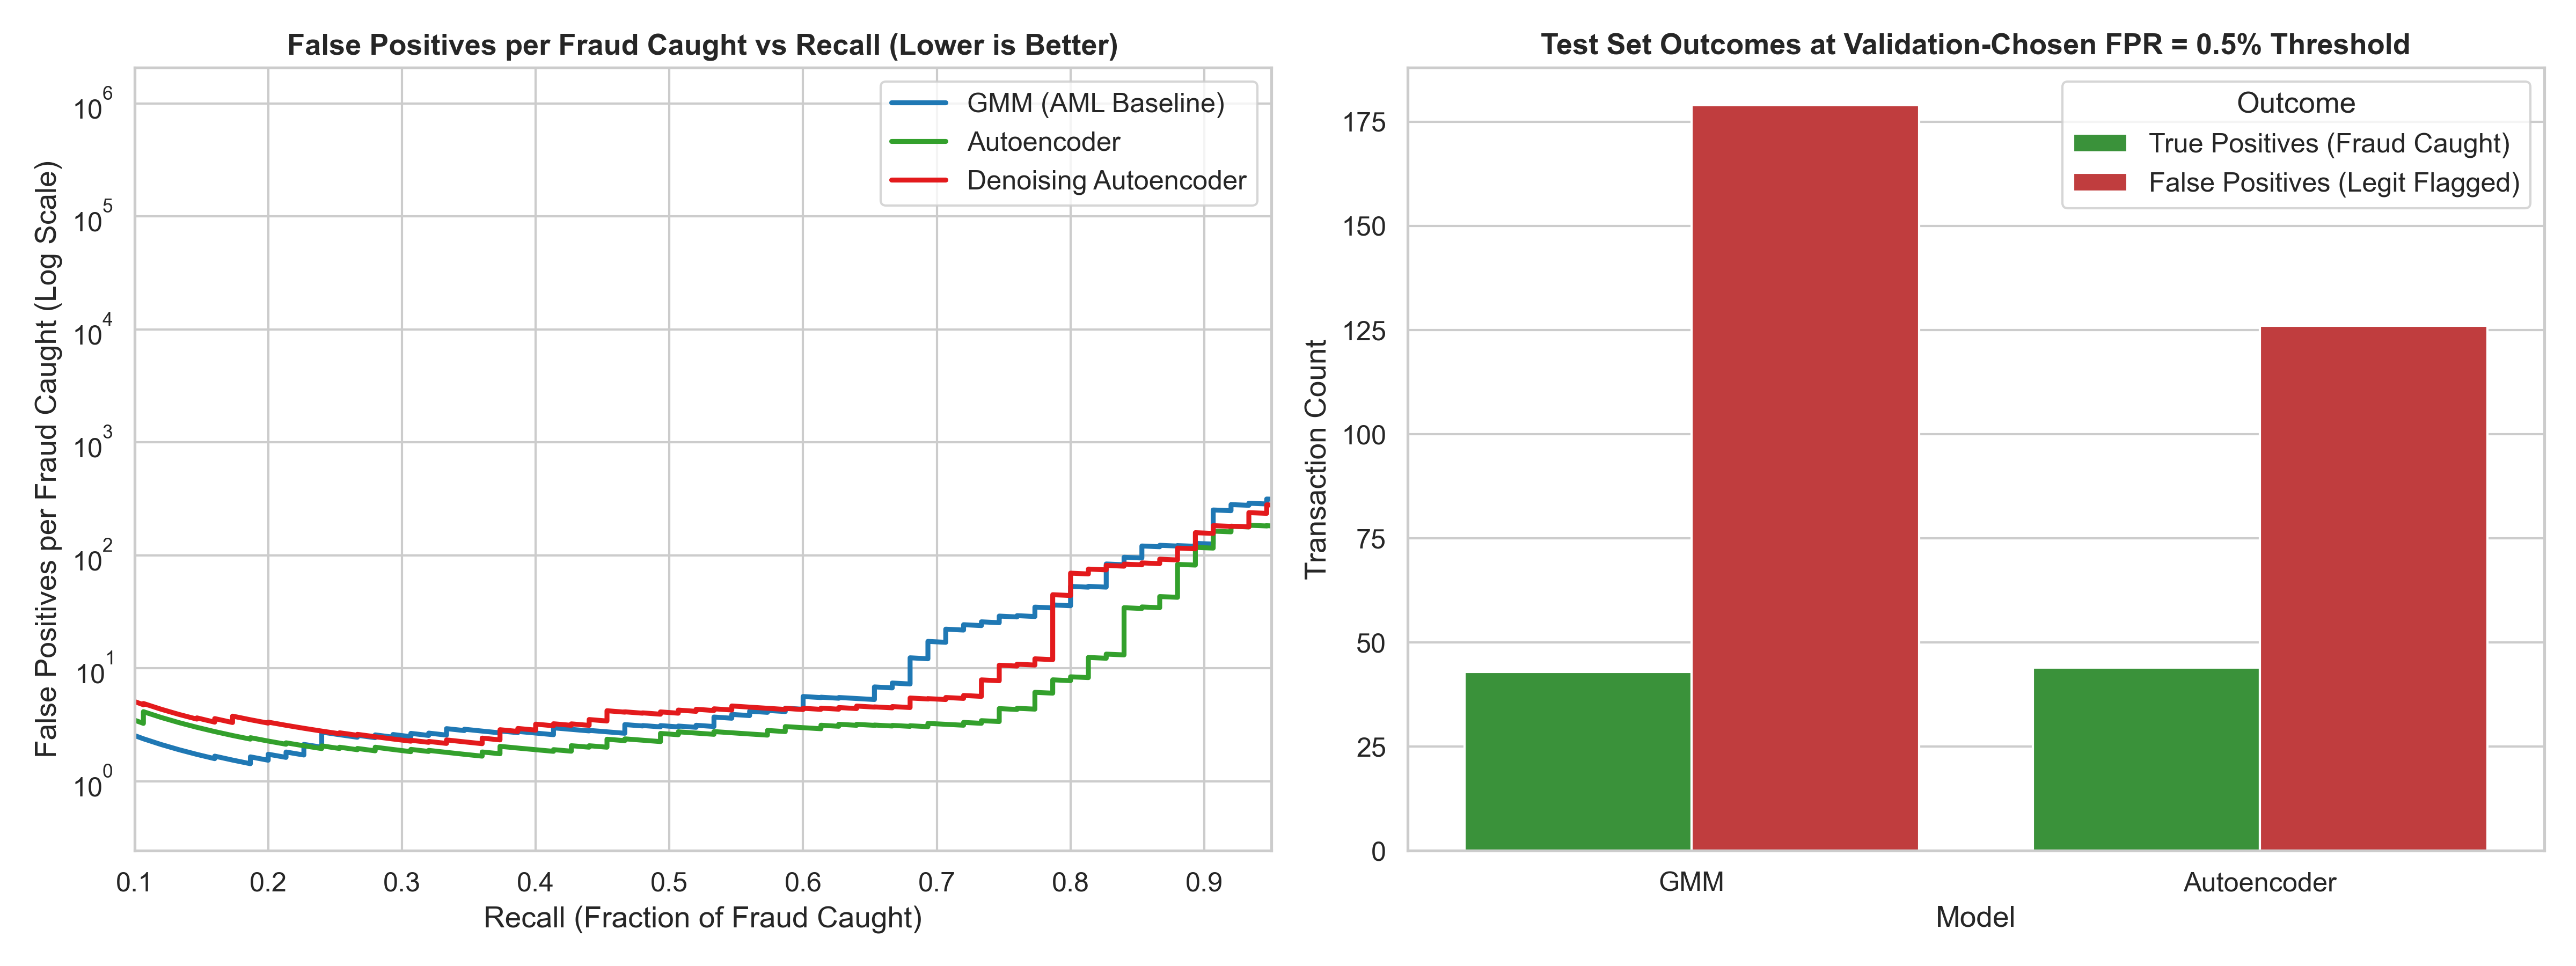

In [2]:
display(Image(filename=os.path.join(repo_root, "outputs/figures/threshold_tradeoff.png")))

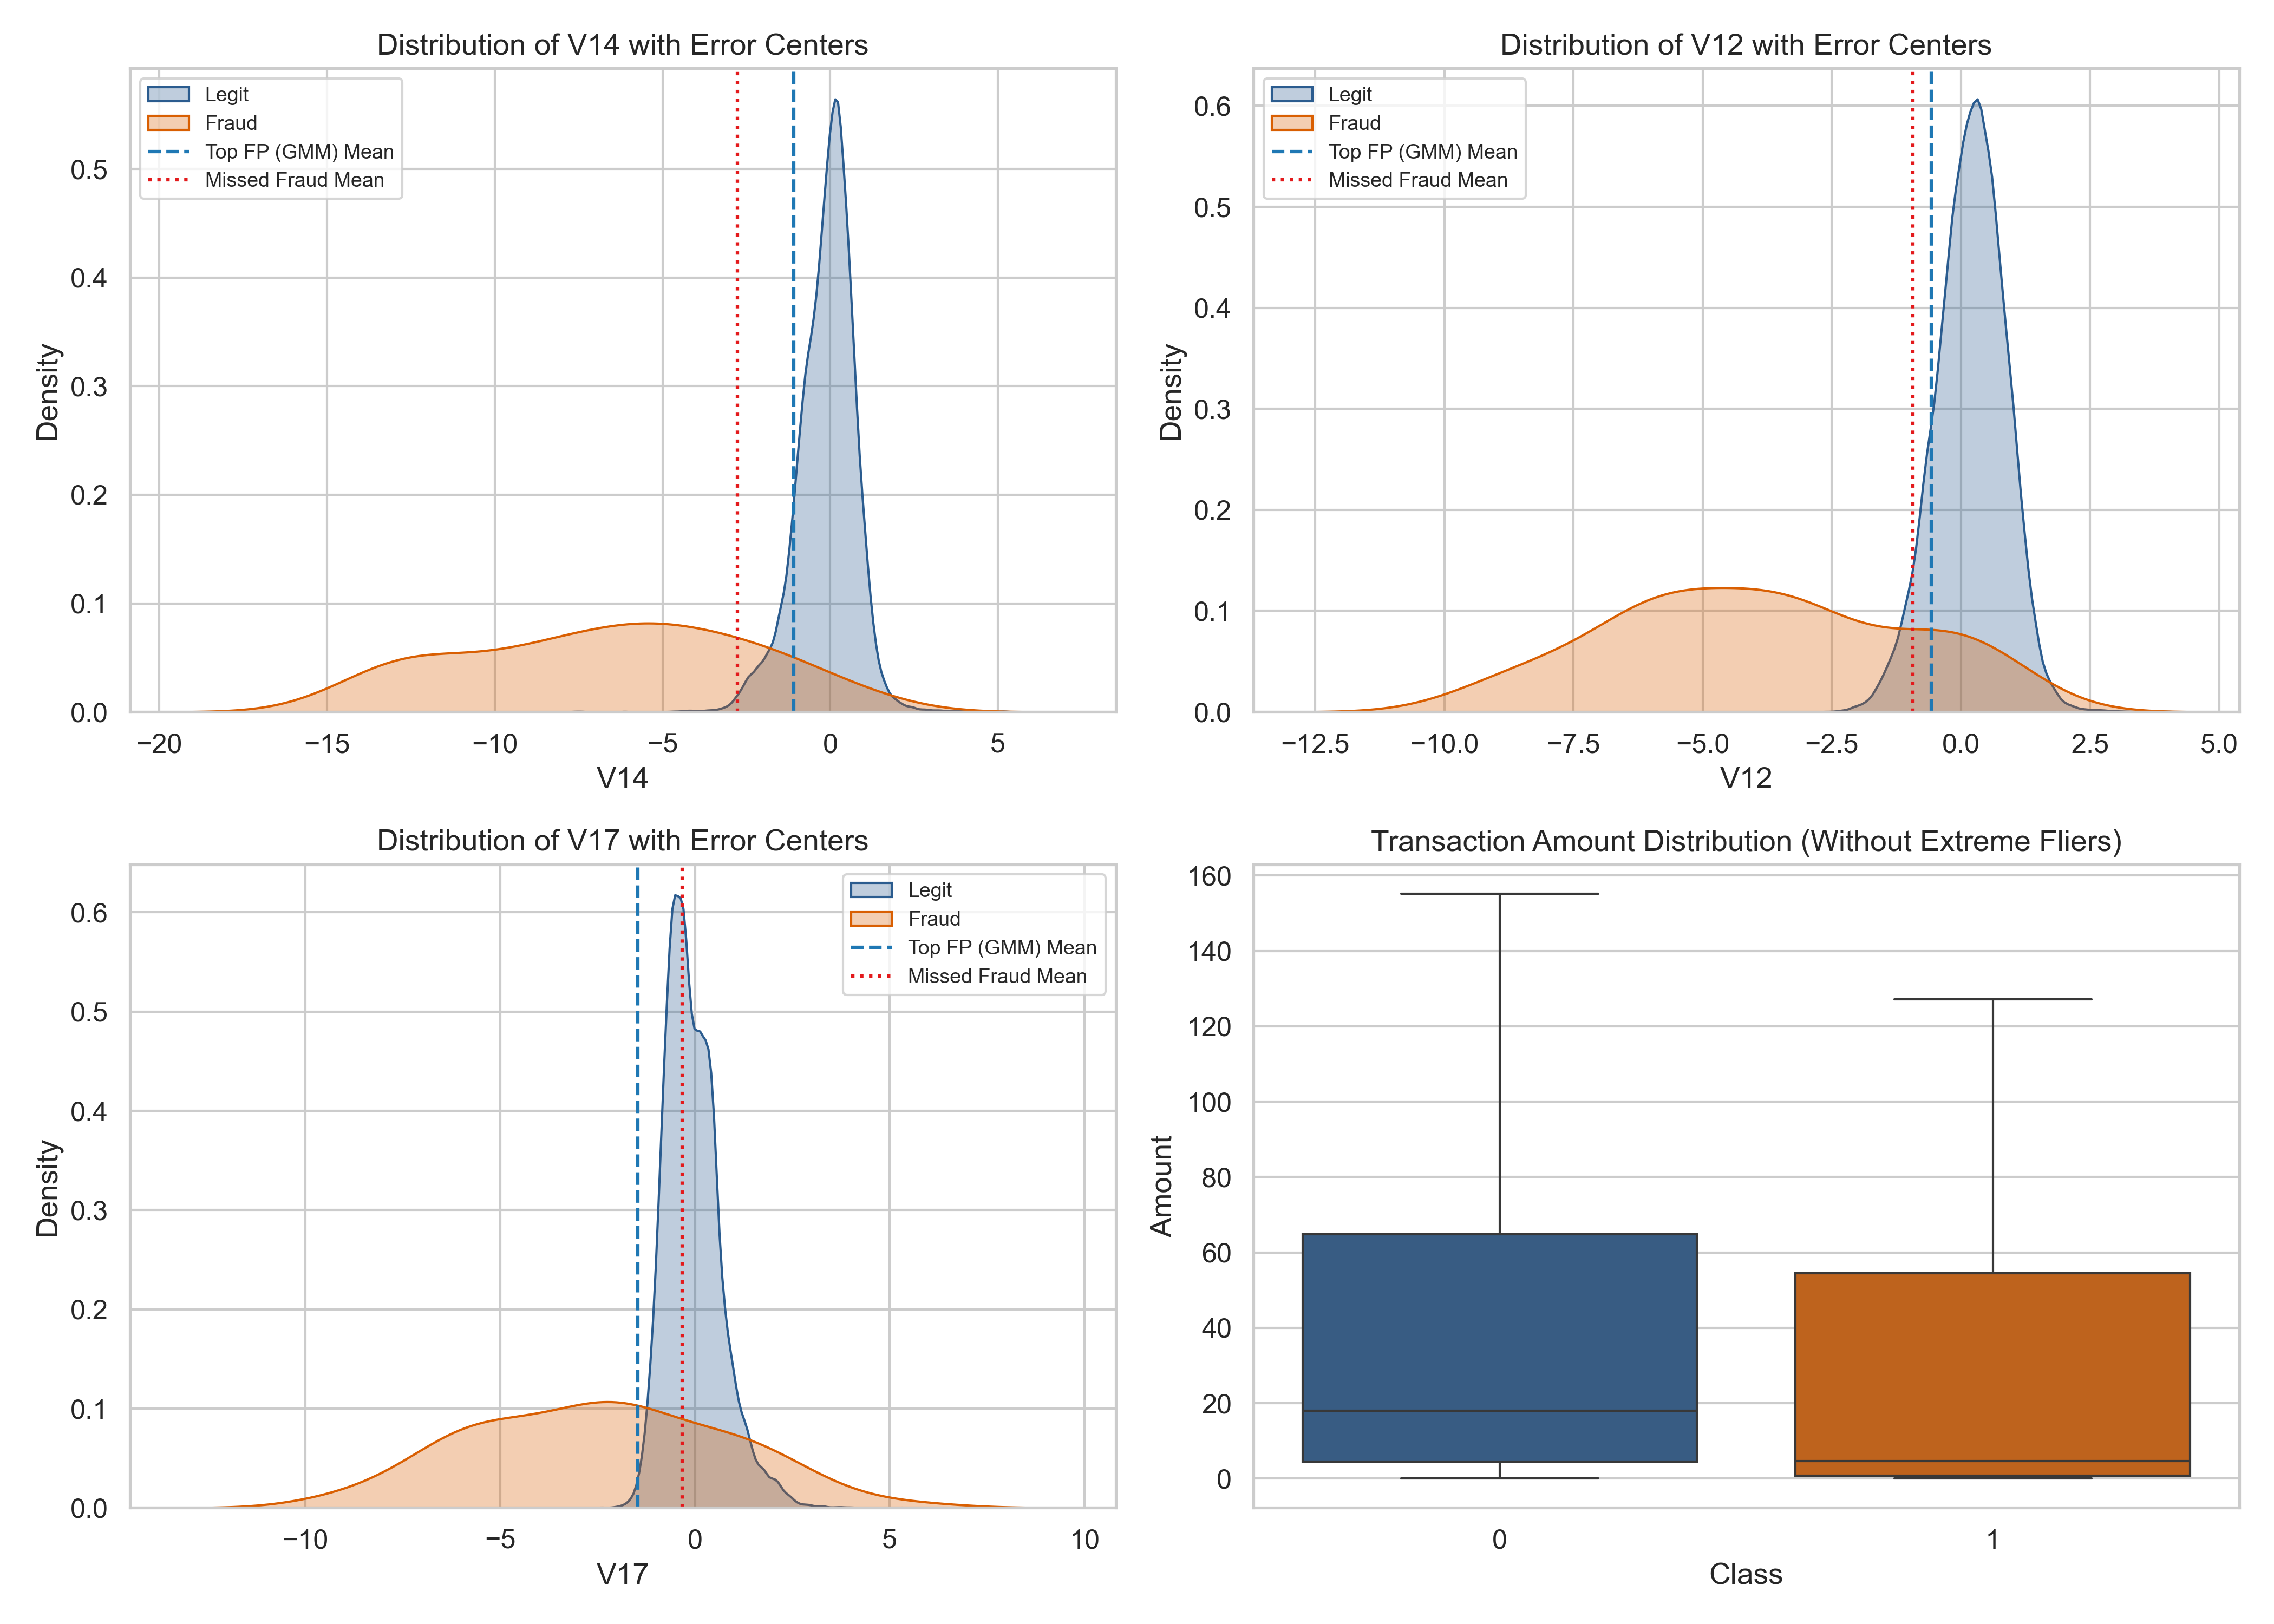

In [3]:
display(Image(filename=os.path.join(repo_root, "outputs/figures/error_analysis.png")))